In [1]:
!pip install numpy pandas matplotlib seaborn requests

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import requests

print("All libraries imported successfully!")

All libraries imported successfully!


In [3]:
data = {
    'Student': ['Aman', 'Riya', 'Rahul', 'Priya', 'Aman',
                'Neha', 'Karan', 'Simran'],
    'Age': [19, 20, 19, 21, 19, np.nan, 22, 20],
    'Marks': [85, 92, 76, 88, 85, 67, np.nan, 95],
    'Attendance': [90, 95, 82, 91, 90, 78, np.nan, 96],
    'Department': ['ECE', 'CSE', 'ECE', 'IT', 'ECE',
                   'CSE', 'IT', 'ECE']
}

df = pd.DataFrame(data)

print("Dataset Created Successfully!")
display(df)

Dataset Created Successfully!


,Student,Age,Marks,Attendance,Department
0,Aman,19.0,85.0,90.0,ECE
1,Riya,20.0,92.0,95.0,CSE
2,Rahul,19.0,76.0,82.0,ECE
3,Priya,21.0,88.0,91.0,IT
4,Aman,19.0,85.0,90.0,ECE
5,Neha,NaN,67.0,78.0,CSE
6,Karan,22.0,NaN,NaN,IT
7,Simran,20.0,95.0,96.0,ECE


In [4]:
print("Dataset Information:")
df.info()

print("\nDataset Shape:")
print(df.shape)

print("\nStatistical Description:")
display(df.describe())

print("\nMissing Values:")
print(df.isnull().sum())

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8 entries, 0 to 7
Data columns (total 5 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   Student     8 non-null      object 
 1   Age         7 non-null      float64
 2   Marks       7 non-null      float64
 3   Attendance  7 non-null      float64
 4   Department  8 non-null      object 
dtypes: float64(3), object(2)
memory usage: 452.0+ bytes

Dataset Shape:
(8, 5)

Statistical Description:


,Age,Marks,Attendance
count,7.000000,7.000000,7.000000
mean,20.000000,84.000000,88.857143
std,1.154701,9.626353,6.593648
min,19.000000,67.000000,78.000000
25%,19.000000,80.500000,86.000000
50%,20.000000,85.000000,90.000000
75%,20.500000,90.000000,93.000000
max,22.000000,95.000000,96.000000



Missing Values:
Student       0
Age           1
Marks         1
Attendance    1
Department    0
dtype: int64


In [5]:
# Remove duplicate records
df = df.drop_duplicates()

# Fill missing numerical values with median
df['Age'] = df['Age'].fillna(df['Age'].median())
df['Marks'] = df['Marks'].fillna(df['Marks'].median())
df['Attendance'] = df['Attendance'].fillna(df['Attendance'].median())

# Check missing values again
print("Data Cleaning Completed!")
print(df.isnull().sum())

display(df)

Data Cleaning Completed!
Student       0
Age           0
Marks         0
Attendance    0
Department    0
dtype: int64


,Student,Age,Marks,Attendance,Department
0,Aman,19.0,85.0,90.0,ECE
1,Riya,20.0,92.0,95.0,CSE
2,Rahul,19.0,76.0,82.0,ECE
3,Priya,21.0,88.0,91.0,IT
5,Neha,20.0,67.0,78.0,CSE
6,Karan,22.0,86.5,90.5,IT
7,Simran,20.0,95.0,96.0,ECE


In [6]:
print("Average Marks:", np.mean(df['Marks']))
print("Highest Marks:", np.max(df['Marks']))
print("Lowest Marks:", np.min(df['Marks']))

print("\nDepartment-wise Average Marks:")
display(df.groupby('Department')['Marks'].mean())

print("\nStudents scoring above 80:")
display(df[df['Marks'] > 80])

Average Marks: 84.21428571428571
Highest Marks: 95.0
Lowest Marks: 67.0

Department-wise Average Marks:


,Marks
Department,
CSE,79.500000
ECE,85.333333
IT,87.250000



Students scoring above 80:


,Student,Age,Marks,Attendance,Department
0,Aman,19.0,85.0,90.0,ECE
1,Riya,20.0,92.0,95.0,CSE
3,Priya,21.0,88.0,91.0,IT
6,Karan,22.0,86.5,90.5,IT
7,Simran,20.0,95.0,96.0,ECE


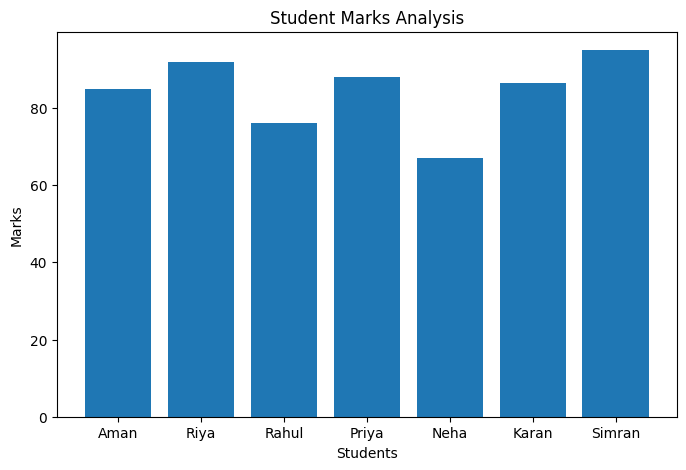

In [7]:
plt.figure(figsize=(8,5))

plt.bar(df['Student'], df['Marks'])

plt.title("Student Marks Analysis")
plt.xlabel("Students")
plt.ylabel("Marks")

plt.show()

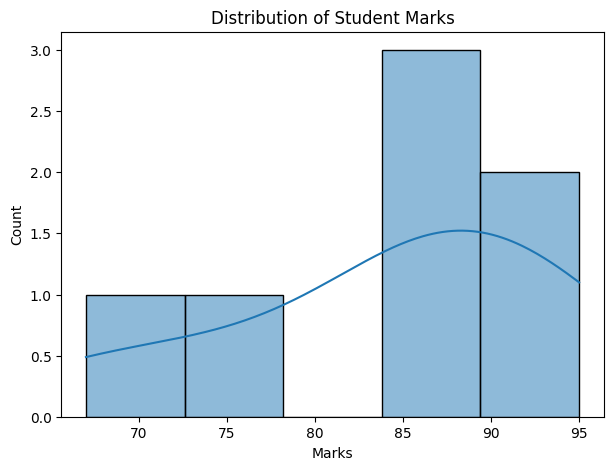

In [8]:
plt.figure(figsize=(7,5))

sns.histplot(df['Marks'], bins=5, kde=True)

plt.title("Distribution of Student Marks")

plt.show()

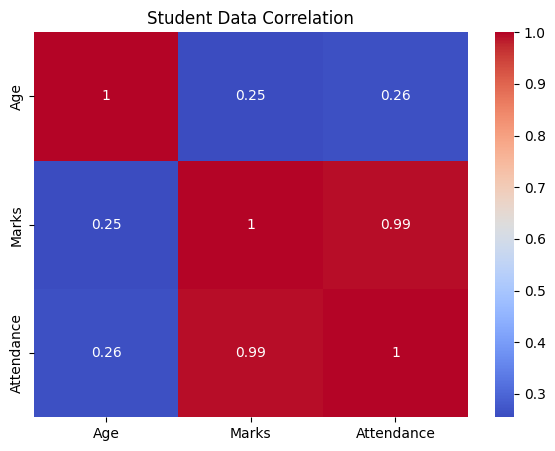

In [13]:
plt.figure(figsize=(7,5))

sns.heatmap(
    df[['Age', 'Marks', 'Attendance']].corr(),
    annot=True,
    cmap='coolwarm'
)

plt.title("Student Data Correlation")

plt.show()

In [11]:
url = "https://jsonplaceholder.typicode.com/posts"

response = requests.get(url)

if response.status_code == 200:
    api_data = response.json()

    print("API Connected Successfully!")

    display(pd.DataFrame(api_data).head(10))
else:
    print("API Error:", response.status_code)

API Connected Successfully!


,userId,id,title,body
0,1,1,sunt aut facere repellat provident occaecati e...,quia et suscipit\nsuscipit recusandae consequu...
1,1,2,qui est esse,est rerum tempore vitae\nsequi sint nihil repr...
2,1,3,ea molestias quasi exercitationem repellat qui...,et iusto sed quo iure\nvoluptatem occaecati om...
3,1,4,eum et est occaecati,ullam et saepe reiciendis voluptatem adipisci\...
4,1,5,nesciunt quas odio,repudiandae veniam quaerat sunt sed\nalias aut...
5,1,6,dolorem eum magni eos aperiam quia,ut aspernatur corporis harum nihil quis provid...
6,1,7,magnam facilis autem,dolore placeat quibusdam ea quo vitae\nmagni q...
7,1,8,dolorem dolore est ipsam,dignissimos aperiam dolorem qui eum\nfacilis q...
8,1,9,nesciunt iure omnis dolorem tempora et accusan...,consectetur animi nesciunt iure dolore\nenim q...
9,1,10,optio molestias id quia eum,quo et expedita modi cum officia vel magni\ndo...


In [12]:
report = df.describe()

report.to_csv("analysis_report.csv")

df.to_csv("cleaned_dataset.csv", index=False)

print("Final Report Generated Successfully!")
print("Files saved:")
print("1. analysis_report.csv")
print("2. cleaned_dataset.csv")

Final Report Generated Successfully!
Files saved:
1. analysis_report.csv
2. cleaned_dataset.csv


In [10]:
report = df.describe()

report.to_csv("analysis_report.csv")

df.to_csv("cleaned_dataset.csv", index=False)

print("Final Report Generated Successfully!")
print("Files saved:")
print("1. analysis_report.csv")
print("2. cleaned_dataset.csv")

Final Report Generated Successfully!
Files saved:
1. analysis_report.csv
2. cleaned_dataset.csv
